> **ARCHIVED — do not use to learn or reproduce the geometry.** This is the first teaching notebook; its saved outputs are kept as a record.
> Known problems, all fixed in [`notebooks/01_geometry.ipynb`](notebooks/01_geometry.ipynb) and tested in `tests/test_geometry.py`:
> - `apply_torsion` rotates about a **global z axis** through one atom, not about the selected bond, and assumes atoms *later in the array* are downstream of the bond (it does not use the molecular graph).
> - The toy coordinates are an **integer** NumPy array; rotated floats are truncated when written back (for the 45° example one edge shrinks from 1.4142 to 1.0).
> - The RDKit example uses torsion indices that are not a bonded four-atom path (`[1, 2, 3, 4]` raises `ValueError`; `[2, 3, 4, 5]` is not contiguous either).
> - The unweighted mean of the coordinates is called a "center of mass"; it is a **centroid**.
> - The torsion "animation" is a toy chain rotating about z, not a molecule rotating about a bond.
> - The trailing cells (`condacolab`, `pip install -r DiffDock/requirements.txt`) belong to the docking notebook, which now has a pinned setup.


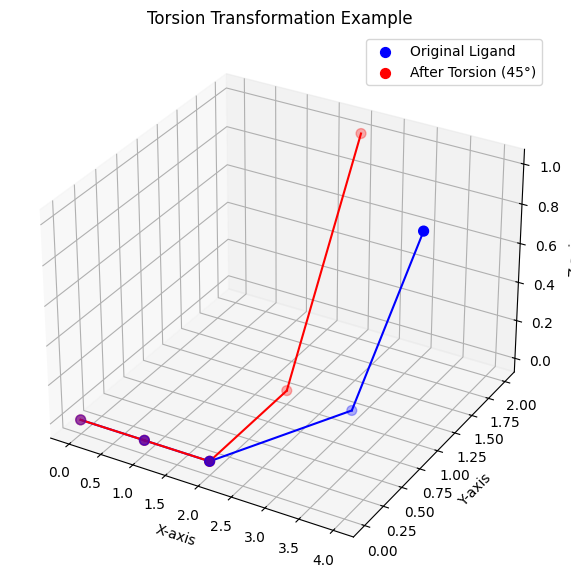

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Helper function to plot ligand
def plot_ligand(ax, atoms, color='blue', label=None):
    x, y, z = atoms[:, 0], atoms[:, 1], atoms[:, 2]
    ax.scatter(x, y, z, c=color, label=label, s=50)
    for i in range(len(x) - 1):
        ax.plot([x[i], x[i + 1]], [y[i], y[i + 1]], [z[i], z[i + 1]], color=color)

# Generate a simple ligand structure (chain of atoms in 3D)
def generate_ligand():
    return np.array([
        [0, 0, 0],
        [1, 0, 0],
        [2, 0, 0],
        [3, 1, 0],
        [4, 1, 1]
    ])

# Define a rotation matrix around z-axis (torsion example)
def rotation_matrix_z(theta):
    return np.array([
        [np.cos(theta), -np.sin(theta), 0],
        [np.sin(theta), np.cos(theta), 0],
        [0, 0, 1]
    ])

# Apply torsion transformation around a bond
def apply_torsion(ligand, bond_idx, angle):
    rotated_ligand = ligand.copy()
    rotation_center = ligand[bond_idx]  # Point of rotation
    rotation_matrix = rotation_matrix_z(angle)  # Torsion around Z-axis

    # Apply rotation to all atoms after the bond
    for i in range(bond_idx + 1, len(ligand)):
        rotated_ligand[i] = rotation_center + rotation_matrix @ (ligand[i] - rotation_center)

    return rotated_ligand

# Generate ligand and apply transformations
ligand = generate_ligand()
torsion_angle = np.pi / 4  # Rotate by 45 degrees
rotated_ligand = apply_torsion(ligand, bond_idx=2, angle=torsion_angle)

# Visualize original and transformed ligand
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

plot_ligand(ax, ligand, color='blue', label='Original Ligand')
plot_ligand(ax, rotated_ligand, color='red', label='After Torsion (45°)')

ax.set_title("Torsion Transformation Example")
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_zlabel("Z-axis")
ax.legend()
plt.show()


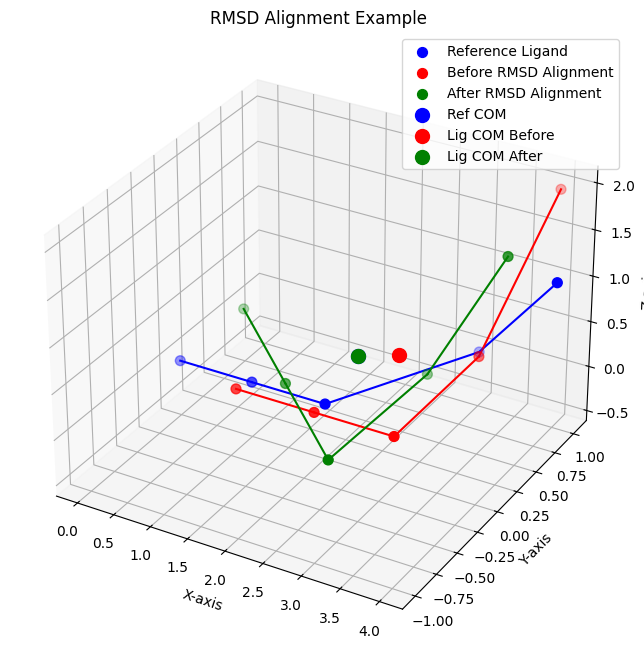

In [2]:
from scipy.spatial.transform import Rotation as R

# Function to calculate the center of mass
def calculate_center_of_mass(ligand):
    return np.mean(ligand, axis=0)

# Function to align two ligands using RMSD minimization
def rmsd_align(reference, ligand):
    # Translate both ligands to their centers of mass
    ref_com = calculate_center_of_mass(reference)
    lig_com = calculate_center_of_mass(ligand)
    ref_centered = reference - ref_com
    lig_centered = ligand - lig_com

    # Compute optimal rotation using Singular Value Decomposition (SVD)
    H = lig_centered.T @ ref_centered
    U, _, Vt = np.linalg.svd(H)
    rotation_matrix = Vt.T @ U.T
    if np.linalg.det(rotation_matrix) < 0:
        Vt[-1, :] *= -1
        rotation_matrix = Vt.T @ U.T

    # Rotate the ligand
    aligned_ligand = (rotation_matrix @ lig_centered.T).T + ref_com
    return aligned_ligand, ref_com, lig_com

# Generate a reference ligand and a transformed ligand
reference_ligand = generate_ligand()
rotated_ligand = apply_torsion(reference_ligand, bond_idx=2, angle=np.pi / 4)
rotated_ligand += np.array([2, -1, 1])  # Add arbitrary translation to the rotated ligand

# Perform RMSD alignment
aligned_ligand, ref_com, lig_com = rmsd_align(reference_ligand, rotated_ligand)

# Plot the reference, transformed, and aligned ligands
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Reference ligand (blue)
plot_ligand(ax, reference_ligand, color='blue', label='Reference Ligand')

# Transformed ligand before alignment (red)
plot_ligand(ax, rotated_ligand, color='red', label='Before RMSD Alignment')

# Aligned ligand (green)
plot_ligand(ax, aligned_ligand, color='green', label='After RMSD Alignment')

# Highlight centers of mass
ax.scatter(*ref_com, c='blue', s=100, label='Ref COM')
ax.scatter(*lig_com, c='red', s=100, label='Lig COM Before')
ax.scatter(*calculate_center_of_mass(aligned_ligand), c='green', s=100, label='Lig COM After')

ax.set_title("RMSD Alignment Example")
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_zlabel("Z-axis")
ax.legend()
plt.show()


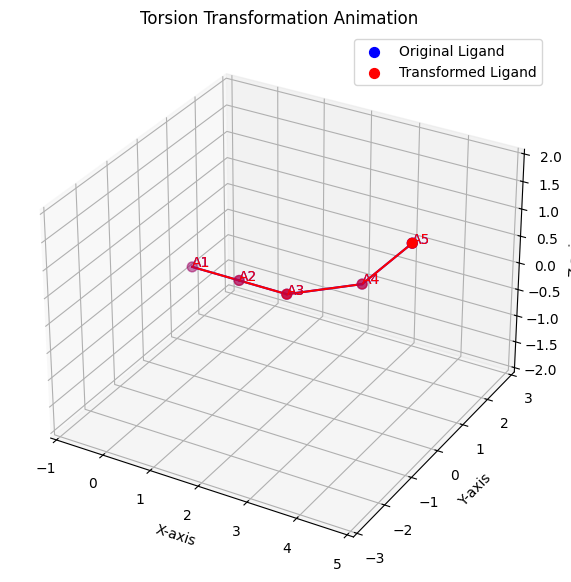

In [3]:
import matplotlib.animation as animation

# Atom labels for clarity
atom_labels = ['A1', 'A2', 'A3', 'A4', 'A5']

# Helper function to add atom labels
def add_labels(ax, atoms, labels, color='black'):
    for i, (x, y, z) in enumerate(atoms):
        ax.text(x, y, z, labels[i], color=color, fontsize=10)

# Animation function for torsion transformation
def animate_torsion(i, ligand, bond_idx, ax):
    ax.clear()
    angle = np.radians(i)  # Incrementally increase angle
    transformed_ligand = apply_torsion(ligand, bond_idx, angle)

    # Plot original and transformed ligand with labels
    plot_ligand(ax, ligand, color='blue', label='Original Ligand')
    plot_ligand(ax, transformed_ligand, color='red', label='Transformed Ligand')
    add_labels(ax, ligand, atom_labels, color='blue')
    add_labels(ax, transformed_ligand, atom_labels, color='red')

    # Set plot limits and labels
    ax.set_xlim(-1, 5)
    ax.set_ylim(-3, 3)
    ax.set_zlim(-2, 2)
    ax.set_title("Torsion Transformation Animation")
    ax.set_xlabel("X-axis")
    ax.set_ylabel("Y-axis")
    ax.set_zlabel("Z-axis")
    ax.legend()

# Setup for animation
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
bond_idx = 2  # Apply torsion around the 2nd bond

ani = animation.FuncAnimation(
    fig, animate_torsion, frames=360, fargs=(ligand, bond_idx, ax), interval=50, blit=False
)

# Save animation as a file or display inline
ani.save('./torsion_transformation.mp4', writer='ffmpeg', fps=30)


In [4]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.8/32.8 MB 39.0 MB/s eta 0:00:00


In [5]:
!pip install py3Dmol

In [6]:
from rdkit import Chem
from rdkit.Chem import AllChem

# Load a molecule
mol = Chem.MolFromSmiles('CC(C)CCO')  # A small ligand
mol = Chem.AddHs(mol)  # Add hydrogens
AllChem.EmbedMolecule(mol)  # Generate 3D coordinates

# Rotate a torsion (assuming bond indices are known)
torsion_indices = [1, 2, 3, 4]  # Atom indices forming the torsion
AllChem.SetDihedralDeg(mol.GetConformer(), *torsion_indices, 45.0)  # Rotate by 45 degrees


ValueError: atoms j and k must be bonded

In [7]:
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

# Function to visualize a molecule in 3D
def show_in_3D(mol):
    mol_block = Chem.MolToMolBlock(mol)
    viewer = py3Dmol.view(width=400, height=400)
    viewer.addModel(mol_block, "mol")  # Load the molecule
    viewer.setStyle({"stick": {}})
    viewer.zoomTo()
    return viewer

# Load a molecule (e.g., isopropanol) and add hydrogens
smiles = "CC(C)CCO"  # Example ligand
mol = Chem.MolFromSmiles(smiles)
mol = Chem.AddHs(mol)  # Add hydrogens
AllChem.EmbedMolecule(mol)  # Generate a 3D conformer

# Define the torsion indices (e.g., atoms [C2, C3, C4, O5])
torsion_indices = [2, 3, 4, 5]  # Adjust for your molecule
conformer = mol.GetConformer()

# Capture the molecule BEFORE torsion rotation
viewer_before = show_in_3D(mol)

# Apply a torsion rotation (e.g., +45 degrees)
initial_angle = AllChem.GetDihedralDeg(conformer, *torsion_indices)
AllChem.SetDihedralDeg(conformer, *torsion_indices, initial_angle + 45)

# Capture the molecule AFTER torsion rotation
viewer_after = show_in_3D(mol)

# Display before and after in 3D
print("Before Torsion Rotation:")
viewer_before.show()

print("After Torsion Rotation (+45 degrees):")
viewer_after.show()


Before Torsion Rotation:


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

After Torsion Rotation (+45 degrees):


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [9]:
!git clone https://github.com/gcorso/DiffDock.git

Cloning into 'DiffDock'...
remote: Enumerating objects: 517, done.
remote: Counting objects: 100% (511/511), done.
remote: Compressing objects: 100% (318/318), done.
remote: Total 517 (delta 244), reused 401 (delta 191), pack-reused 6 (from 1)
Receiving objects: 100% (517/517), 233.08 MiB | 33.09 MiB/s, done.
Resolving deltas: 100% (244/244), done.


In [11]:
!pip install -q condacolab

In [12]:
!cd DiffDock

In [15]:
!pip install -r DiffDock/requirements.txt

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu117
Looking in links: https://pytorch-geometric.com/whl/torch-1.13.1+cu117.html
  Cloning https://github.com/NVIDIA/dllogger.git to /tmp/pip-install-rqmwsqmp/dllogger_5a0b47e00e2f408b852ff4266bf83648
  Running command git clone --filter=blob:none --quiet https://github.com/NVIDIA/dllogger.git /tmp/pip-install-rqmwsqmp/dllogger_5a0b47e00e2f408b852ff4266bf83648
  Resolved https://github.com/NVIDIA/dllogger.git to commit 0540a43971f4a8a16693a9de9de73c1072020769
  Preparing metadata (setup.py) ... done
  Cloning https://github.com/aqlaboratory/openfold.git (to revision 4b41059694619831a7db195b7e0988fc4ff3a307) to /tmp/pip-install-rqmwsqmp/openfold_127ff4e36c654c68a65985519297e718
  Running command git clone --filter=blob:none --quiet https://github.com/aqlaboratory/openfold.git /tmp/pip-install-rqmwsqmp/openfold_127ff4e36c654c68a65985519297e718
  Running command git rev-parse -q --verify 'sha^4b41059694619831a7